# 线性回归课堂笔记：从相关分析到模型评估

本 Notebook 按《机器学习课堂笔记(4)》和《机器学习课堂笔记(5)》整理，覆盖：

- conda 环境与 Jupyter 内核
- 广告投放案例：相关系数、散点图
- 假设函数、sklearn 要求的数据形状
- 单特征 / 多特征线性回归
- 预测、MAE / RMSE / R² 与残差图
- 损失函数、最小二乘法与正规方程

数据：`data/广告数据.csv`（200 周，微信/微博/抖音投入与销售额）。

依赖：

```bash
pip install numpy pandas scikit-learn matplotlib
```

> 本 Notebook 位于 `notebooks/` 目录，数据路径统一写作 `../data/广告数据.csv`；如果在项目根目录运行，请改成 `data/广告数据.csv`。

## 0. conda 环境与 Jupyter 内核

每个 conda 环境是一套独立隔离的 Python + 包版本，环境之间互不干扰。`base` 是 Anaconda 默认环境，项目依赖建议单独建环境。

### 0.1 常用命令

```bash
# 查看所有环境（同时能看到安装位置）
conda env list

# 创建环境
conda create -n 环境名称

# 创建时直接装好 Python 和 Jupyter 内核
conda create -n 环境名称 python=3.12 ipykernel -y

# 激活 / 退出
conda activate 环境名称
conda deactivate

# 删除环境（先退出要删除的环境）
conda env remove -n 环境名称
```

### 0.2 把环境注册到 Jupyter

Jupyter 默认不知道你新建的 conda 环境，需要注册内核：

```bash
conda activate 环境名称
python -m ipykernel install --user --name 项目名 --display-name "Jupyter 中显示的名称"
```

- `--name`：内核的唯一标识，建议用英文；
- `--display-name`：Jupyter 下拉框中显示的名字，可以用中文；
- 注册后刷新或重启 Jupyter，才能看到新内核。

查看和删除内核：

```bash
jupyter kernelspec list
jupyter kernelspec remove 内核名称
```

注意：`jupyter kernelspec remove` 用的是**内核名称**（`--name` 的值），不是 conda 环境名称。

> Python 版本建议 3.11 / 3.12。笔记里写的 Python 3.14 很新，部分科学计算包可能尚未完全适配。

## 1. 从分类到回归

- **分类**：输出类别，例如“这朵花是哪个品种”。
- **回归**：输出连续数值，例如“这周销售额是多少万元”。

线性回归就是找一条最贴合数据的直线（或多个特征时的超平面），描述特征与标签之间的近似线性关系，再用它做预测。

### 广告案例的 T、P、E

一家网店记录了 200 周的数据：每周在微信、微博、抖音三个渠道各投多少钱（千元），这一周卖了多少钱（万元）。

- **T（任务）**：根据三个渠道的投入预测销售额；
- **P（性能）**：预测值与真实值平均差多少万元（如 MAE、RMSE）；
- **E（经验）**：200 周的历史记录。

要预测的是一个连续的数，所以这是**回归问题**。

In [1]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
np.set_printoptions(precision=4, suppress=True)

In [2]:
# Notebook 位于 notebooks/ 目录，因此用 ../data 回到项目根目录
df = pd.read_csv("../data/广告数据.csv")
print("数据形状:", df.shape)
df.head()

数据形状: (200, 4)


,微信,微博,抖音,销售额
0,102.3,6.9,16.4,12.8
1,173.4,37.8,50.5,21.6
2,161.6,41.8,30.8,22.7
3,108.5,4.5,22.9,9.6
4,271.7,22.0,21.3,20.0


In [3]:
df.describe().round(2)

,微信,微博,抖音,销售额
count,200.00,200.00,200.00,200.00
mean,147.65,24.85,33.56,16.14
std,80.57,14.43,15.30,4.51
min,1.30,0.20,2.50,1.00
25%,84.30,13.28,24.05,12.50
50%,150.10,25.40,31.90,16.55
75%,210.12,37.65,41.82,19.40
max,295.30,49.70,97.90,25.30


## 2. 相关系数：两个量同涨同跌的程度

皮尔逊相关系数 $r$ 用来衡量两个变量是否同步变化：

$$r=\frac{\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})}
{\sqrt{\sum_{i=1}^{n}(x_i-\bar{x})^2}\sqrt{\sum_{i=1}^{n}(y_i-\bar{y})^2}}$$

- 分子：每个点的 $x$ 偏差与 $y$ 偏差相乘再求和；
- 分母：归一化，把结果压缩到 $[-1, 1]$，消除单位和量级影响；
- $r>0$ 正相关，$r<0$ 负相关，$r\approx 0$ 几乎没有线性关系。

**相关不等于因果**：两个变量一起变化，不代表其中一个导致了另一个。

In [4]:
corr = df.corr(numeric_only=True)
corr.round(3)

,微信,微博,抖音,销售额
微信,1.000,-0.033,-0.085,0.768
微博,-0.033,1.000,0.550,0.503
抖音,-0.085,0.550,1.000,0.211
销售额,0.768,0.503,0.211,1.000


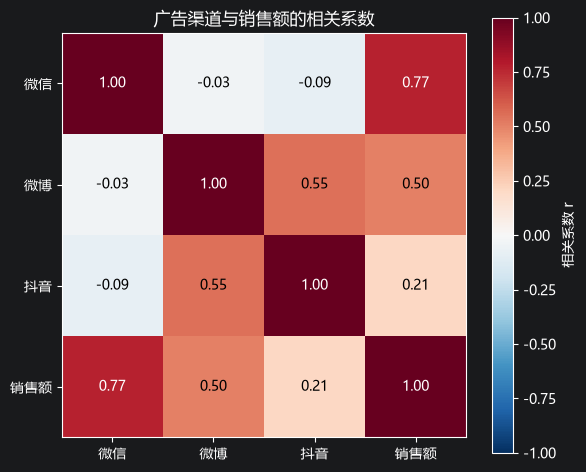

In [5]:
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)

ax.set_xticks(range(len(corr.columns)), corr.columns)
ax.set_yticks(range(len(corr.index)), corr.index)
ax.set_title("广告渠道与销售额的相关系数")

for i in range(len(corr)):
    for j in range(len(corr)):
        value = corr.iloc[i, j]
        color = "white" if abs(value) > 0.55 else "black"
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", color=color)

fig.colorbar(im, ax=ax, label="相关系数 r")
plt.tight_layout()
plt.show()

### 相关系数怎么读

- 微信与销售额：`r ≈ 0.768`，最强正相关；
- 微博与销售额：`r ≈ 0.503`，中等正相关；
- 抖音与销售额：`r ≈ 0.211`，弱正相关；
- 微博与抖音之间：`r ≈ 0.550`，说明老板往往同时加大这两个渠道的投入。

最后一点很重要：微博和抖音之间存在**多重共线性**。在多元回归里，这会让两个渠道的系数变得不稳定，不要单独过度解释某一个系数。

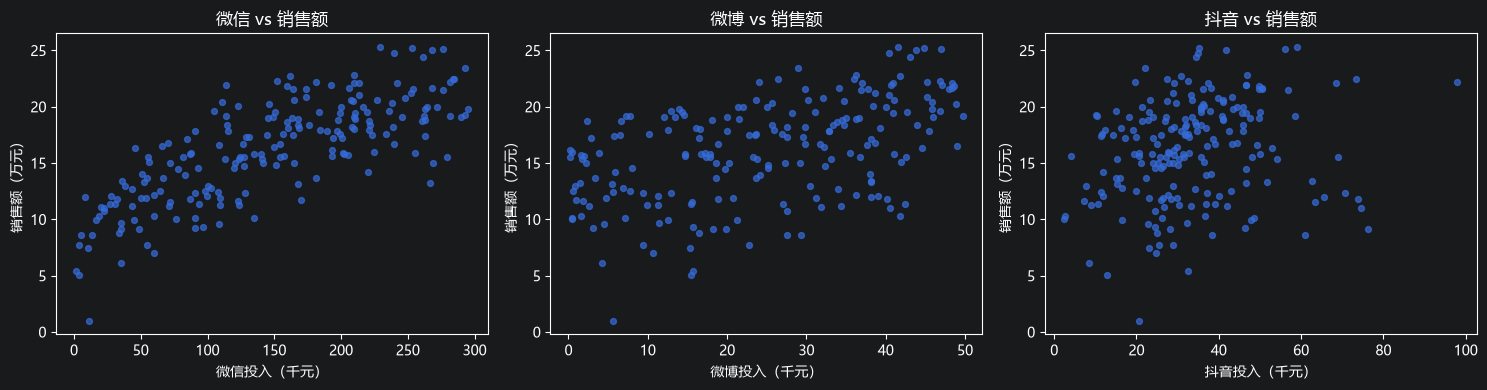

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, ["微信", "微博", "抖音"]):
    ax.scatter(df[col], df["销售额"], s=18, alpha=0.7)
    ax.set_xlabel(f"{col}投入（千元）")
    ax.set_ylabel("销售额（万元）")
    ax.set_title(f"{col} vs 销售额")

plt.tight_layout()
plt.show()

## 3. 假设函数：一条直线

单特征时，最简单的假设是销售额与微信投入呈直线关系：

$$\hat{y}=wx+b$$

- $x$：这一周的微信投入（千元）；
- $\hat{y}$：模型预测的销售额（万元），帽子表示“估计值”；
- $w$：权重（斜率），表示 $x$ 每增加 1，$\hat{y}$ 增加多少；
- $b$：偏置（截距），表示 $x=0$ 时的基准值。

有 $d$ 个特征时，直线推广成超平面：

$$\hat{y}=w_1x_1+w_2x_2+\cdots+w_dx_d+b=\mathbf{w}^{\top}\mathbf{x}+b$$

### sklearn 要求的数据形状

- `X`：二维数组，形状 `(样本数, 特征数)`，即使只有一个特征也不能是一维；
- `y`：一维数组，形状 `(样本数,)`。

`df['微信']` 是 Series（一维）；`df[['微信']]` 是 DataFrame（二维）。

In [7]:
X = df[["微信"]]
y = df["销售额"]

print("X 形状:", X.shape)
print("y 形状:", y.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("训练集:", X_train.shape, "测试集:", X_test.shape)

X 形状: (200, 1)
y 形状: (200,)
训练集: (160, 1) 测试集: (40, 1)


In [8]:
model = LinearRegression().fit(X_train, y_train)

w = model.coef_[0]
b = model.intercept_

print(f"权重 w = {w:.4f}")
print(f"偏置 b = {b:.4f}")
print(f"假设函数: 销售额 = {w:.4f} × 微信投入 + {b:.4f}")

权重 w = 0.0429
偏置 b = 9.6064
假设函数: 销售额 = 0.0429 × 微信投入 + 9.6064


In [9]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE  : {mae:.3f} 万元")
print(f"RMSE : {rmse:.3f} 万元")
print(f"R²   : {r2:.3f}")
print(f"训练集 R²: {model.score(X_train, y_train):.3f}")

MAE  : 2.362 万元
RMSE : 2.898 万元
R²   : 0.551
训练集 R²: 0.596


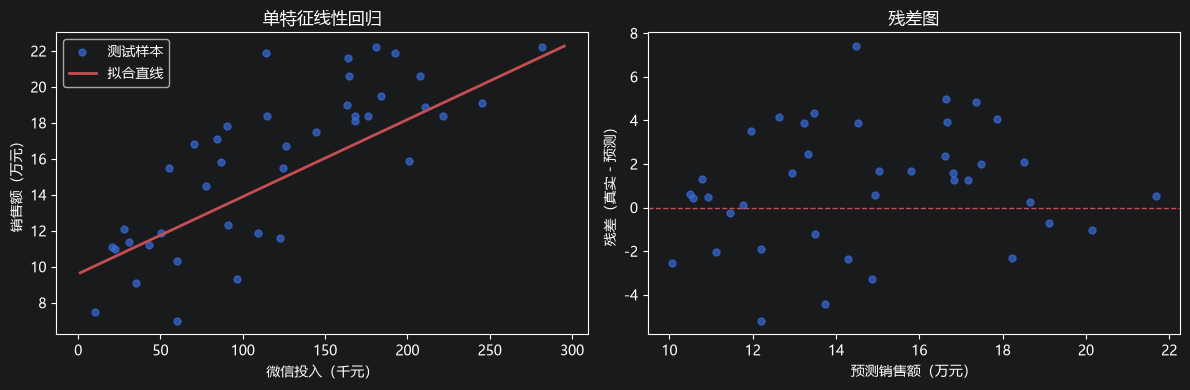

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# 左图：测试样本 + 拟合直线
axes[0].scatter(X_test["微信"], y_test, s=25, alpha=0.7, label="测试样本")
x_line = np.linspace(df["微信"].min(), df["微信"].max(), 100)
y_line = model.predict(pd.DataFrame({"微信": x_line}))
axes[0].plot(x_line, y_line, color="#C44E52", linewidth=2, label="拟合直线")
axes[0].set_xlabel("微信投入（千元）")
axes[0].set_ylabel("销售额（万元）")
axes[0].set_title("单特征线性回归")
axes[0].legend()

# 右图：残差图
residuals = y_test - y_pred
axes[1].scatter(y_pred, residuals, s=25, alpha=0.7)
axes[1].axhline(0, color="#C44E52", linestyle="--", linewidth=1)
axes[1].set_xlabel("预测销售额（万元）")
axes[1].set_ylabel("残差（真实 - 预测）")
axes[1].set_title("残差图")

plt.tight_layout()
plt.show()

### 单特征模型怎么读

- $w$ 的单位是“万元 / 千元”：微信每多投 1 千元，销售额平均增加 $w$ 万元；
- $b$ 是截距，表示微信投入为 0 时的基准销售额；
- $R^2$ 表示模型解释了测试集销售额波动的比例，越接近 1 越好；
- 残差图应围绕 0 随机分布；如果出现明显曲线或喇叭形，说明线性假设可能不够。

## 4. 多特征线性回归

把三个渠道一起放进模型：

$$\hat{y}=w_1x_{\text{微信}}+w_2x_{\text{微博}}+w_3x_{\text{抖音}}+b$$

每个系数表示**控制其他渠道不变**时，该渠道每多投 1 千元，销售额平均变化多少万元。

In [11]:
X_multi = df[["微信", "微博", "抖音"]]
y = df["销售额"]

X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_multi, y, test_size=0.2, random_state=42
)

model_multi = LinearRegression().fit(X_train_m, y_train_m)

coef_table = pd.DataFrame({
    "特征": X_multi.columns,
    "系数（万元/千元）": model_multi.coef_,
})
coef_table

,特征,系数（万元/千元）
0,微信,0.043242
1,微博,0.167022
2,抖音,-0.006217


In [12]:
for name, coef in zip(X_multi.columns, model_multi.coef_):
    print(f"{name}: 每多投 1 千元，销售额约变化 {coef * 10000:.0f} 元（控制其他渠道不变）")
print(f"截距 b = {model_multi.intercept_:.4f} 万元")

微信: 每多投 1 千元，销售额约变化 432 元（控制其他渠道不变）
微博: 每多投 1 千元，销售额约变化 1670 元（控制其他渠道不变）
抖音: 每多投 1 千元，销售额约变化 -62 元（控制其他渠道不变）
截距 b = 5.7487 万元


In [13]:
y_pred_m = model_multi.predict(X_test_m)

print(f"MAE  : {mean_absolute_error(y_test_m, y_pred_m):.3f} 万元")
print(f"RMSE : {np.sqrt(mean_squared_error(y_test_m, y_pred_m)):.3f} 万元")
print(f"测试集 R²: {r2_score(y_test_m, y_pred_m):.3f}")
print(f"训练集 R²: {model_multi.score(X_train_m, y_train_m):.3f}")

MAE  : 1.403 万元
RMSE : 1.643 万元
测试集 R²: 0.856
训练集 R²: 0.873


In [14]:
comparison = pd.DataFrame({
    "模型": ["微信单特征", "三渠道多特征"],
    "测试集 MAE": [
        mean_absolute_error(y_test, y_pred),
        mean_absolute_error(y_test_m, y_pred_m),
    ],
    "测试集 RMSE": [
        np.sqrt(mean_squared_error(y_test, y_pred)),
        np.sqrt(mean_squared_error(y_test_m, y_pred_m)),
    ],
    "测试集 R²": [
        r2_score(y_test, y_pred),
        r2_score(y_test_m, y_pred_m),
    ],
})
comparison.round(3)

,模型,测试集 MAE,测试集 RMSE,测试集 R²
0,微信单特征,2.362,2.898,0.551
1,三渠道多特征,1.403,1.643,0.856


In [15]:
# 下周计划：微信 200 千元、微博 30 千元、抖音 40 千元
new_week = pd.DataFrame({"微信": [200], "微博": [30], "抖音": [40]})
predicted_sales = model_multi.predict(new_week)[0]
print(f"预测销售额: {predicted_sales:.2f} 万元")

预测销售额: 19.16 万元


## 5. 损失函数与最小二乘法

### 5.1 残差与均方误差

对第 $i$ 个样本，真实值与预测值之差叫**残差**：

$$e_i=y_i-\hat{y}_i$$

残差有正有负，直接相加会互相抵消。最常用的办法是先平方再平均，得到**均方误差**（Mean Squared Error，MSE）：

$$\text{MSE}=\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2$$

训练数据 $x_i,y_i$ 是固定的，能变的只有 $w$ 和 $b$，所以损失是参数的函数：

$$L(w,b)=\frac{1}{n}\sum_{i=1}^{n}(y_i-wx_i-b)^2$$

训练就是找一组 $(w,b)$，让 $L(w,b)$ 最小。

### 5.2 为什么是平方，不是绝对值？

另一个自然选择是**平均绝对误差**（Mean Absolute Error，MAE）：

$$\text{MAE}=\frac{1}{n}\sum_{i=1}^{n}|y_i-\hat{y}_i|$$

| 指标 | 优点 | 缺点 |
|---|---|---|
| MSE | 处处光滑可导，对线性模型是凸“碗”，满列秩时最低点唯一 | 误差平方会放大离群点，对异常值敏感 |
| MAE | 对离群点更稳健 | 在误差为 0 处不可导，最优解可能不唯一 |
| Huber | 兼顾两者 | 多一个超参数需要设置 |

线性回归默认用 MSE；异常值很多时可以考虑 MAE 或 Huber。

### 5.3 最小二乘闭式解

对 $b$ 求偏导并令其为 0：

$$\frac{\partial L}{\partial b}=0
\quad\Rightarrow\quad
b=\bar{y}-w\bar{x}$$

这说明最优直线一定穿过平均点 $(\bar{x},\bar{y})$。再对 $w$ 求偏导并令其为 0：

$$w=\frac{\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})}
{\sum_{i=1}^{n}(x_i-\bar{x})^2}$$

这就是**最小二乘法**的闭式解。

In [16]:
# 用训练集比较两条候选直线的 MSE
X_train_np = np.asarray(X_train, dtype=float)
y_train_np = np.asarray(y_train, dtype=float)

def predict_line(X, w, b):
    return w * X[:, 0] + b

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

print("两条候选直线的训练集 MSE：")
for w, b in [(0.1, 0), (0.04, 10)]:
    y_hat = predict_line(X_train_np, w, b)
    print(f"w={w:<5} b={b:<3} MSE={mse(y_train_np, y_hat):.3f}")

两条候选直线的训练集 MSE：
w=0.1   b=0   MSE=30.627
w=0.04  b=10  MSE=8.360


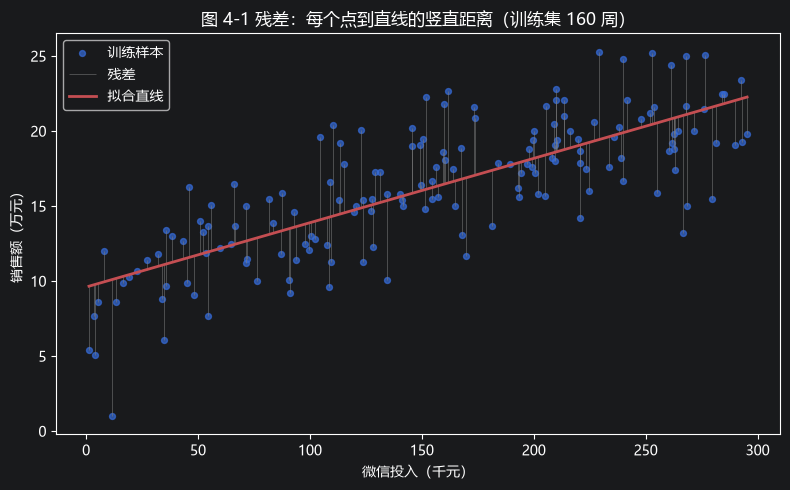

In [17]:
# 图 4-1：残差 = 每个训练样本到拟合直线的竖直距离
y_train_pred = model.predict(X_train)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(X_train_np[:, 0], y_train_np, s=18, alpha=0.7, label="训练样本")
ax.vlines(
    X_train_np[:, 0],
    np.minimum(y_train_np, y_train_pred),
    np.maximum(y_train_np, y_train_pred),
    color="gray",
    linewidth=0.6,
    alpha=0.6,
    label="残差",
)
x_line = np.linspace(X_train_np[:, 0].min(), X_train_np[:, 0].max(), 100)
y_line = model.predict(pd.DataFrame({"微信": x_line}))
ax.plot(x_line, y_line, color="#C44E52", linewidth=2, label="拟合直线")
ax.set_xlabel("微信投入（千元）")
ax.set_ylabel("销售额（万元）")
ax.set_title("图 4-1 残差：每个点到直线的竖直距离（训练集 160 周）")
ax.legend()
plt.tight_layout()
plt.show()

**讲义原图 4-1：残差**

残差就是每个训练样本到拟合直线的竖直距离。

![图 4-1 残差：每个点到直线的竖直距离（训练集 160 周）](images/notes5_fig4_1_residuals.png)

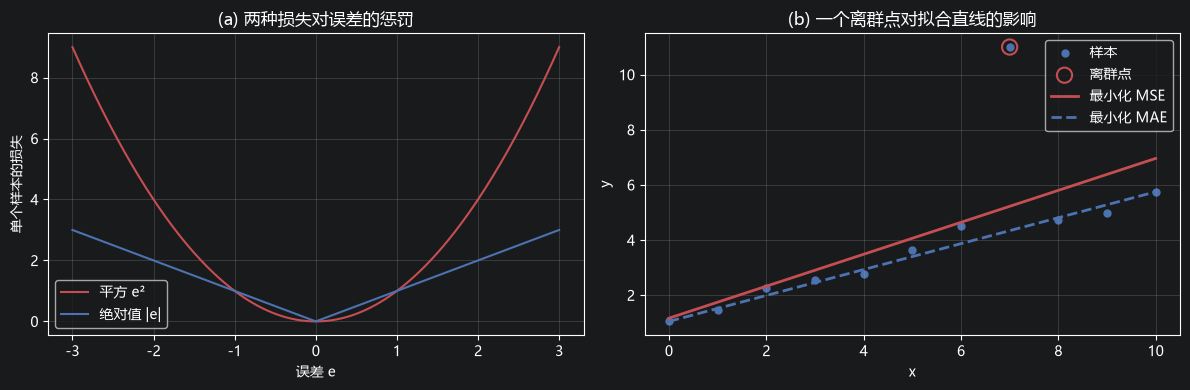

In [18]:
# 图 4-2：MSE 与 MAE 的对比（右图用模拟数据展示离群点的影响）
from sklearn.linear_model import QuantileRegressor

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# (a) 两种损失对误差的惩罚
errors = np.linspace(-3, 3, 400)
axes[0].plot(errors, errors ** 2, color="#C44E52", label="平方 e²")
axes[0].plot(errors, np.abs(errors), color="#4C72B0", label="绝对值 |e|")
axes[0].set_xlabel("误差 e")
axes[0].set_ylabel("单个样本的损失")
axes[0].set_title("(a) 两种损失对误差的惩罚")
axes[0].legend()
axes[0].grid(alpha=0.3)

# (b) 一个离群点对拟合直线的影响
rng = np.random.default_rng(0)
x_demo = np.arange(11, dtype=float)
y_demo = 0.5 * x_demo + 1 + rng.normal(0, 0.4, size=x_demo.size)
y_demo[7] = 11.0  # 人为加入一个离群点
X_demo = x_demo.reshape(-1, 1)

mse_model = LinearRegression().fit(X_demo, y_demo)
mae_model = QuantileRegressor(quantile=0.5, alpha=0, solver="highs").fit(X_demo, y_demo)

axes[1].scatter(x_demo, y_demo, s=25, color="#4C72B0", label="样本")
axes[1].scatter([7], [11], s=120, facecolors="none", edgecolors="#C44E52", linewidth=1.5, label="离群点")
xx = np.linspace(0, 10, 100).reshape(-1, 1)
axes[1].plot(xx, mse_model.predict(xx), color="#C44E52", linewidth=2, label="最小化 MSE")
axes[1].plot(xx, mae_model.predict(xx), color="#4C72B0", linestyle="--", linewidth=2, label="最小化 MAE")
axes[1].set_xlabel("x")
axes[1].set_ylabel("y")
axes[1].set_title("(b) 一个离群点对拟合直线的影响")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

**讲义原图 4-2：MSE 与 MAE**

- (a) 平方误差对大误差的惩罚更重；
- (b) 一个离群点对两条最优直线的影响：MSE 更容易被离群点拉偏。

![图 4-2 MSE 与 MAE](images/notes5_fig4_2_mse_vs_mae.png)

In [19]:
# 一元最小二乘闭式解，并与 sklearn 对照
x = X_train_np[:, 0]
x_bar = x.mean()
y_bar = y_train_np.mean()

w_ls = np.sum((x - x_bar) * (y_train_np - y_bar)) / np.sum((x - x_bar) ** 2)
b_ls = y_bar - w_ls * x_bar

print(f"闭式解: w={w_ls:.4f}, b={b_ls:.4f}")
print(f"闭式解训练集 MSE: {mse(y_train_np, predict_line(X_train_np, w_ls, b_ls)):.3f}")
print(f"sklearn: w={model.coef_[0]:.4f}, b={model.intercept_:.4f}")
print("两者是否一致:", np.allclose([w_ls, b_ls], [model.coef_[0], model.intercept_]))

闭式解: w=0.0429, b=9.6064
闭式解训练集 MSE: 8.302
sklearn: w=0.0429, b=9.6064
两者是否一致: True


## 6. 多特征：正规方程

多个特征时，把样本排成设计矩阵 $X$，并在最后补一列 1：

$$X=
\begin{bmatrix}
x_{11} & \cdots & x_{1d} & 1\\
\vdots & & \vdots & \vdots\\
x_{n1} & \cdots & x_{nd} & 1
\end{bmatrix},
\qquad
\theta=
\begin{bmatrix}
w_1\\ \vdots\\ w_d\\ b
\end{bmatrix}
$$

预测值和损失写成：

$$\hat{\mathbf{y}}=X\theta,
\qquad
L(\theta)=\frac{1}{n}\|\mathbf{y}-X\theta\|^2$$

对 $\theta$ 求梯度并令其为零，得到**正规方程**：

$$X^{\top}X\theta=X^{\top}\mathbf{y}$$

当 $X^{\top}X$ 可逆时：

$$\theta=(X^{\top}X)^{-1}X^{\top}\mathbf{y}$$

### 为什么要补最后一列 1？

- 不补 1：模型是 $\hat{y}=w_1x_1+\cdots+w_dx_d$，强制过原点；
- 补 1：第 $d+1$ 个权重就是偏置 $b$，$X\theta$ 自动算出 $\sum w_jx_j+b$。

sklearn 的 `LinearRegression(fit_intercept=True)` 会在内部自动完成这件事。

In [20]:
# 多特征正规方程：给设计矩阵补一列 1
X_train_m_np = np.asarray(X_train_m, dtype=float)
X_test_m_np = np.asarray(X_test_m, dtype=float)
y_train_m_np = np.asarray(y_train_m, dtype=float)

X_design_train = np.c_[X_train_m_np, np.ones(len(X_train_m_np))]
X_design_test = np.c_[X_test_m_np, np.ones(len(X_test_m_np))]

XtX = X_design_train.T @ X_design_train
theta_inv = np.linalg.inv(XtX) @ X_design_train.T @ y_train_m_np
theta_lstsq = np.linalg.lstsq(X_design_train, y_train_m_np, rcond=None)[0]

print("正规方程 inv  :", np.round(theta_inv, 4))
print("正规方程 lstsq:", np.round(theta_lstsq, 4))
print("sklearn       :", np.round(np.r_[model_multi.coef_, model_multi.intercept_], 4))
print("条件数 cond(XᵀX):", round(np.linalg.cond(XtX), 1))

正规方程 inv  : [ 0.0432  0.167  -0.0062  5.7487]
正规方程 lstsq: [ 0.0432  0.167  -0.0062  5.7487]
sklearn       : [ 0.0432  0.167  -0.0062  5.7487]
条件数 cond(XᵀX): 335071.0


In [21]:
# 正规方程与 sklearn 的预测对照
pred_theta = X_design_test @ theta_inv
pred_sklearn = model_multi.predict(X_test_m)
print("正规方程与 sklearn 预测的最大差异:", np.max(np.abs(pred_theta - pred_sklearn)))

# 不补 1 列：模型强制过原点
theta_no_bias = np.linalg.lstsq(X_train_m_np, y_train_m_np, rcond=None)[0]
print("不补 1 的系数:", np.round(theta_no_bias, 4))
print("训练集 MSE（补 1）:", round(mse(y_train_m_np, X_design_train @ theta_inv), 3))
print("训练集 MSE（不补 1）:", round(mse(y_train_m_np, X_train_m_np @ theta_no_bias), 3))

正规方程与 sklearn 预测的最大差异: 3.197442310920451e-14
不补 1 的系数: [0.0568 0.1884 0.0735]
训练集 MSE（补 1）: 2.606
训练集 MSE（不补 1）: 5.746


### 正规方程的局限

1. $X^{\top}X$ 必须可逆；特征严重共线时可能奇异或病态。本例 $X^{\top}X$ 的条件数约为 $3.35\times10^5$，说明特征尺度差异和微博/抖音相关性让矩阵偏病态，系数解释要谨慎。
2. 计算 $X^{\top}X$ 的复杂度约为 $O(nd^2)$，求逆约为 $O(d^3)$；样本量或特征数很大时计算慢、占内存，此时改用梯度下降。
3. 适合样本不多、特征数量不大的场景，可以一步求解，不用迭代。
4. 共线性严重时，可以用 Ridge 正则化或删除冗余特征。

## 7. 结果解读与注意点

### 结果

- 单特征（微信）测试集 $R^2 \approx 0.551$；
- 三渠道多特征测试集 $R^2 \approx 0.856$，加入微博、抖音后明显提升；
- 多特征模型里，微博的系数比微信大，但微信与销售额的**相关系数**更高。这两件事不矛盾：相关系数看的是单独变化，回归系数看的是**控制其他渠道后**的边际贡献；
- 抖音系数接近 0（甚至略为负），说明在微信、微博已经进入模型后，抖音的额外信息很少；
- 微博与抖音相关性 0.55，存在多重共线性，系数解释要谨慎；
- 闭式解和正规方程与 sklearn 的 `LinearRegression` 结果一致；给设计矩阵补一列 1 等价于 `fit_intercept=True`。

### 注意

1. **相关不等于因果**：模型能预测，不代表“多投微博就一定多卖”。
2. **线性假设**：残差图若有明显结构，可能需要对数变换、多项式或交互项。
3. **训练集 / 测试集**：测试集只用于最终评估，不能拿来调参。
4. **异常值**：线性回归对异常值敏感，建模前应先检查散点图。
5. **多重共线性**：相关系数高的特征不要同时过度解释；可用 VIF、正则化（Ridge/Lasso）处理。
6. **正规方程**：要求 $X^{\top}X$ 可逆；样本或特征很大时计算慢，应改用梯度下降。

### 练习

1. 只把微博或只把抖音作为单特征，比较 $R^2$。
2. 对销售额做对数变换，观察 $R^2$ 和残差图是否改善。
3. 加入交互项（如微信 × 微博），看模型是否更好。
4. 用 `cross_val_score` 做 5 折交叉验证，比较单特征与多特征的稳定性。
5. 用 `StandardScaler` 标准化特征后再回归，观察系数变化（预测值不变）。
6. 用正规方程手算多特征系数，并与 sklearn 对照；再去掉 1 列，观察预测和 MSE 的变化。